# Handwritten Digit Recognition (MNIST + CNN)
CodeAlpha Machine Learning Internship, Task 3

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

tf.random.set_seed(42)
np.random.seed(42)

## 1. Load data
MNIST has 70,000 images of handwritten digits (0 to 9). Each image is 28 x 28 pixels. Keras downloads it automatically.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print('Train images:', x_train.shape)
print('Test images:', x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train images: (60000, 28, 28)
Test images: (10000, 28, 28)


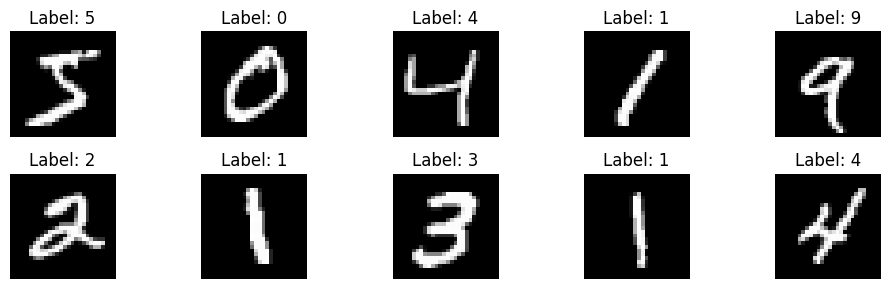

In [3]:
plt.figure(figsize=(10, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title('Label: ' + str(y_train[i]))
    plt.axis('off')
plt.tight_layout()
plt.show()

## 2. Prepare data
Pixel values go from 0 to 255. We divide by 255 so they fall between 0 and 1. CNN also needs a channel dimension.

In [4]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = np.expand_dims(x_train, -1)   # (60000, 28, 28, 1)
x_test = np.expand_dims(x_test, -1)
print(x_train.shape, x_test.shape)

(60000, 28, 28, 1) (10000, 28, 28, 1)


## 3. Build the CNN

In [5]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax'),
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train
10% of training data is kept aside for validation.

In [6]:
history = model.fit(x_train, y_train,
                    epochs=8,
                    batch_size=128,
                    validation_split=0.1,
                    verbose=2)

Epoch 1/8
422/422 - 45s - 106ms/step - accuracy: 0.9254 - loss: 0.2463 - val_accuracy: 0.9842 - val_loss: 0.0586
Epoch 2/8
422/422 - 39s - 92ms/step - accuracy: 0.9781 - loss: 0.0725 - val_accuracy: 0.9878 - val_loss: 0.0439
Epoch 3/8
422/422 - 41s - 98ms/step - accuracy: 0.9841 - loss: 0.0511 - val_accuracy: 0.9895 - val_loss: 0.0374
Epoch 4/8
422/422 - 38s - 91ms/step - accuracy: 0.9871 - loss: 0.0401 - val_accuracy: 0.9913 - val_loss: 0.0336
Epoch 5/8
422/422 - 38s - 90ms/step - accuracy: 0.9890 - loss: 0.0342 - val_accuracy: 0.9910 - val_loss: 0.0322
Epoch 6/8
422/422 - 39s - 92ms/step - accuracy: 0.9905 - loss: 0.0285 - val_accuracy: 0.9913 - val_loss: 0.0289
Epoch 7/8
422/422 - 40s - 95ms/step - accuracy: 0.9921 - loss: 0.0246 - val_accuracy: 0.9910 - val_loss: 0.0341
Epoch 8/8
422/422 - 38s - 89ms/step - accuracy: 0.9926 - loss: 0.0224 - val_accuracy: 0.9917 - val_loss: 0.0309


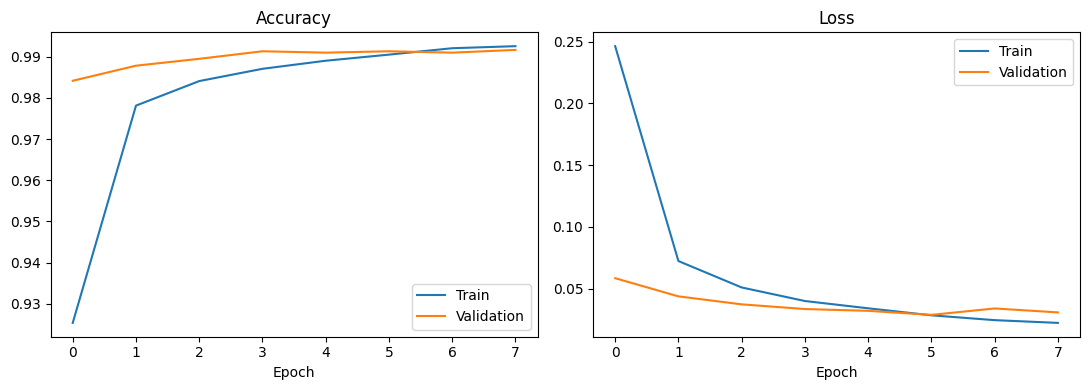

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Evaluate on test data

In [8]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print('Test accuracy:', round(test_acc * 100, 2), '%')

y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred, digits=4))

Test accuracy: 99.1 %
              precision    recall  f1-score   support

           0     0.9899    0.9969    0.9934       980
           1     0.9904    0.9982    0.9943      1135
           2     0.9894    0.9952    0.9923      1032
           3     0.9921    0.9950    0.9936      1010
           4     0.9869    0.9990    0.9929       982
           5     0.9899    0.9854    0.9876       892
           6     0.9937    0.9896    0.9916       958
           7     0.9893    0.9854    0.9873      1028
           8     0.9938    0.9897    0.9918       974
           9     0.9949    0.9742    0.9845      1009

    accuracy                         0.9910     10000
   macro avg     0.9910    0.9909    0.9909     10000
weighted avg     0.9910    0.9910    0.9910     10000



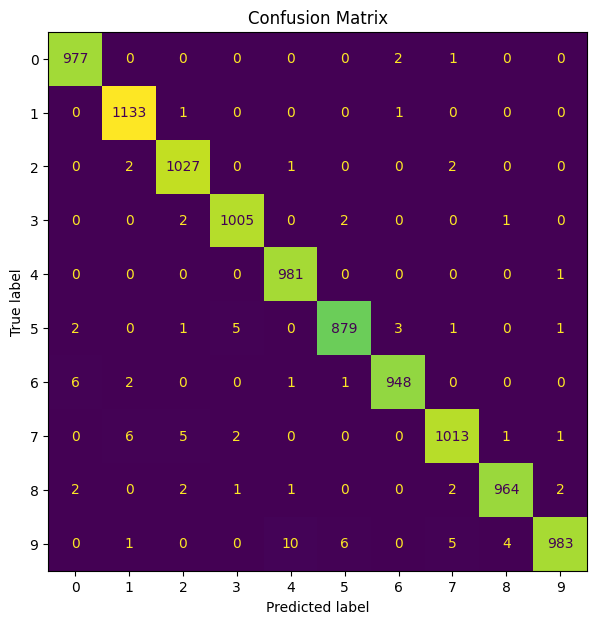

In [9]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay(cm).plot(ax=ax, colorbar=False)
plt.title('Confusion Matrix')
plt.show()

## 6. Look at the mistakes

Wrong predictions: 90 out of 10000


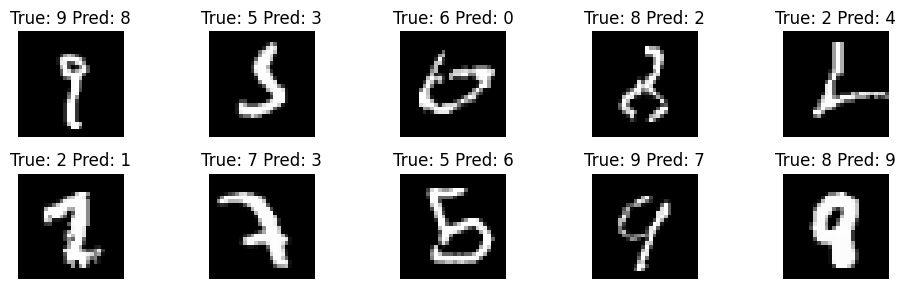

In [10]:
wrong = np.where(y_pred != y_test)[0]
print('Wrong predictions:', len(wrong), 'out of', len(y_test))

plt.figure(figsize=(10, 3))
for i, idx in enumerate(wrong[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
    plt.title('True: ' + str(y_test[idx]) + ' Pred: ' + str(y_pred[idx]))
    plt.axis('off')
plt.tight_layout()
plt.show()

## 7. Test with your own handwriting (optional)
Write one digit with a dark pen on white paper, take a clear photo, crop it to the digit, then upload it here.

Saving photo_2026-10-03_09-28-17.jpg to photo_2026-10-03_09-28-17.jpg


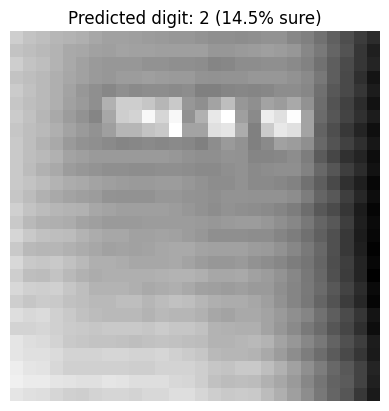

In [11]:
from google.colab import files
from PIL import Image, ImageOps

uploaded = files.upload()
name = list(uploaded.keys())[0]

img = Image.open(name).convert('L')
img = ImageOps.autocontrast(img)
img = ImageOps.invert(img)          # MNIST has white digits on black background
img = img.resize((28, 28))

arr = np.array(img).astype('float32') / 255.0
pred = model.predict(arr.reshape(1, 28, 28, 1), verbose=0)

plt.imshow(arr, cmap='gray')
plt.title('Predicted digit: ' + str(np.argmax(pred)) + ' (' + str(round(float(np.max(pred)) * 100, 1)) + '% sure)')
plt.axis('off')
plt.show()

## 8. Save the model

In [12]:
model.save('mnist_cnn.keras')